# 05 - Explicabilidad con SHAP
## Que variables mueven las predicciones del modelo (Vaca Muerta / YPF)

**Objetivo:** abrir la "caja negra" del modelo final (LightGBM, 8 variables)
y entender **por que** predice lo que predice.

En el notebook 03 vimos la importancia de variables que trae LightGBM por
defecto, pero esa medida solo dice *cuanto se uso* cada variable, no *en que
direccion* empuja la prediccion (si la sube o la baja). SHAP si lo muestra:
para cada prediccion reparte el resultado entre las variables, indicando
cuantos barriles suma o resta cada una respecto del valor promedio.

En el objetivo especifico de la Pre-Entrega 1 queda planteado como
"explicabilidad": identificar que variables influyen mas en la produccion
estimada.

## Paso 0: Imports y configuracion

In [1]:
import sys
import os

sys.path.append("..")

if os.getcwd().endswith("notebooks"):
    os.chdir("..")

print("Carpeta de trabajo actual:", os.getcwd())

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
%matplotlib inline

# Carpeta para guardar los graficos (los vamos a usar en la presentacion)
os.makedirs("reports", exist_ok=True)

Carpeta de trabajo actual: /Users/cristianaguilera/Desktop/proyecto-ds-ypf


## Paso 1: Reconstruir el conjunto de prueba

Para explicar el modelo necesitamos exactamente los mismos datos de prueba
que usamos en el notebook 03. Repetimos los mismos pasos (misma variable
`declinacion_pet_anterior`, mismas columnas, mismo filtro y mismo corte
temporal en 2024).

In [2]:
df = pd.read_csv("data/processed/produccion_con_features.csv")
df = df.sort_values(["idpozo", "anio", "mes"]).reset_index(drop=True)

# Misma variable sin fuga de datos que en el notebook 03
df["declinacion_pet_anterior"] = df.groupby("idpozo")["declinacion_pet"].shift(1)

columnas_features = [
    "antiguedad_meses",
    "prod_pet_mes_anterior",
    "prod_gas_mes_anterior",
    "declinacion_pet_anterior",
    "ratio_gas_petroleo",
    "profundidad",
    "formacion_cod",
    "cuenca_cod",
]
columna_objetivo = "prod_pet"

# Mismo filtro que en el notebook 03: anio completo y sin NaN
df_modelo = df[df["anio_completo"]].copy()
df_modelo = df_modelo.dropna(subset=columnas_features + [columna_objetivo])

# Mismo corte temporal: prueba = 2024 en adelante
anio_corte = 2024
train = df_modelo[df_modelo["anio"] < anio_corte]
test = df_modelo[df_modelo["anio"] >= anio_corte]

X_test = test[columnas_features]
y_test = test[columna_objetivo]

print("Filas de prueba:", len(X_test))

Filas de prueba: 65170


## Paso 2: Cargar el modelo y chequear que es el mismo

Cargamos el modelo guardado en el notebook 03. Antes de explicarlo
verificamos que sus metricas sobre este conjunto de prueba coinciden con
las ya documentadas (RMSE 439.34 y R2 0.888). Si dieran distinto, estariamos
explicando otro modelo o con otros datos.

In [3]:
modelo = joblib.load("models/modelo_produccion_pet.joblib")

predicciones = modelo.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, predicciones))
r2 = r2_score(y_test, predicciones)

print(f"RMSE: {rmse:.2f}  (esperado: 439.34)")
print(f"R2:   {r2:.3f}  (esperado: 0.888)")

RMSE: 439.34  (esperado: 439.34)
R2:   0.888  (esperado: 0.888)


## Paso 3: Calcular los valores SHAP

`TreeExplainer` es la version de SHAP pensada para modelos de arboles como
LightGBM: es exacta y rapida. Calculamos los valores sobre una **muestra
aleatoria de 5.000 filas** del conjunto de prueba: alcanza para ver los
patrones y evita que los graficos tarden demasiado.

Un valor SHAP positivo significa que esa variable **sube** la prediccion de
ese pozo-mes respecto del promedio del modelo; uno negativo, que la **baja**.

In [4]:
explainer = shap.TreeExplainer(modelo)

# Muestra aleatoria (con semilla, para que sea reproducible)
X_muestra = X_test.sample(n=5000, random_state=42)

shap_values = explainer(X_muestra)

print("Valor base (prediccion promedio del modelo):", round(float(np.ravel(shap_values.base_values)[0]), 1))
print("Forma de los valores SHAP:", shap_values.values.shape)

Valor base (prediccion promedio del modelo): 360.4
Forma de los valores SHAP: (5000, 8)


## Paso 4: Importancia global de las variables

Promediamos el **valor absoluto** de SHAP por variable: nos dice cuantos
barriles mueve, en promedio, cada variable en las predicciones (sin importar
si suben o bajan). Es una medida mas interpretable que la importancia
interna de LightGBM, porque esta en las mismas unidades que lo que
predecimos (producciones de petroleo).

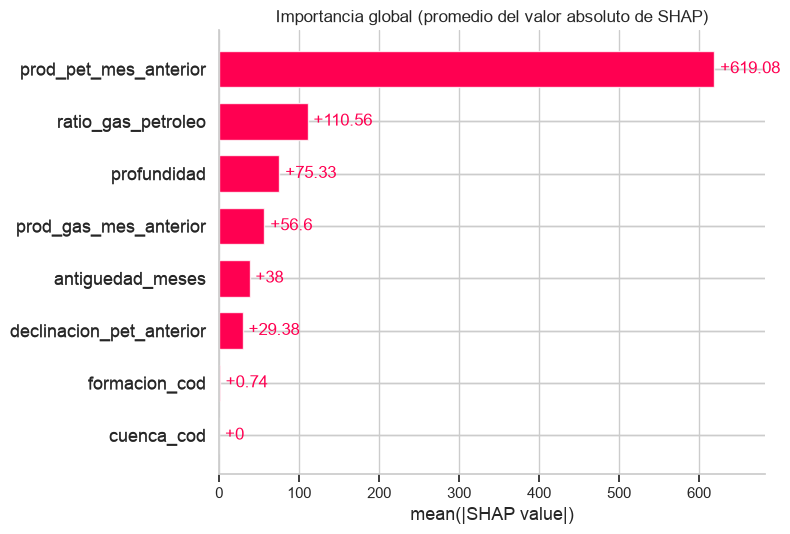

In [5]:
shap.plots.bar(shap_values, show=False)
plt.title("Importancia global (promedio del valor absoluto de SHAP)")
plt.tight_layout()
plt.savefig("reports/shap_importancia_global.png", dpi=150, bbox_inches="tight")
plt.show()

**Comparacion con la importancia de LightGBM (notebook 03):** en el
notebook 03 vimos que ambos modelos coincidian en que
`prod_pet_mes_anterior` era la variable dominante. Aca revisamos si SHAP
confirma ese ranking y si aparece alguna diferencia en el orden del resto de
las variables.

In [6]:
# Tabla con ambas medidas, ordenadas por SHAP
importancia_shap = pd.Series(
    np.abs(shap_values.values).mean(axis=0), index=columnas_features
)
importancia_lgbm = pd.Series(modelo.feature_importances_, index=columnas_features)

comparacion_importancias = pd.DataFrame({
    "SHAP (promedio |valor|, en barriles)": importancia_shap.round(1),
    "LightGBM (cantidad de splits)": importancia_lgbm,
}).sort_values("SHAP (promedio |valor|, en barriles)", ascending=False)

comparacion_importancias

,"SHAP (promedio |valor|, en barriles)",LightGBM (cantidad de splits)
prod_pet_mes_anterior,619.1,991
ratio_gas_petroleo,110.6,832
profundidad,75.3,824
prod_gas_mes_anterior,56.6,712
antiguedad_meses,38.0,625
declinacion_pet_anterior,29.4,870
formacion_cod,0.7,11
cuenca_cod,0.0,0


## Paso 5: Direccion del efecto de cada variable (beeswarm)

Cada punto es un pozo-mes. En el eje horizontal se ve cuanto sube (derecha)
o baja (izquierda) la prediccion, y el color indica si el valor de la variable
era alto (rojo) o bajo (azul). Asi se ve, por ejemplo, si un valor alto de
produccion del mes anterior empuja la prediccion hacia arriba.

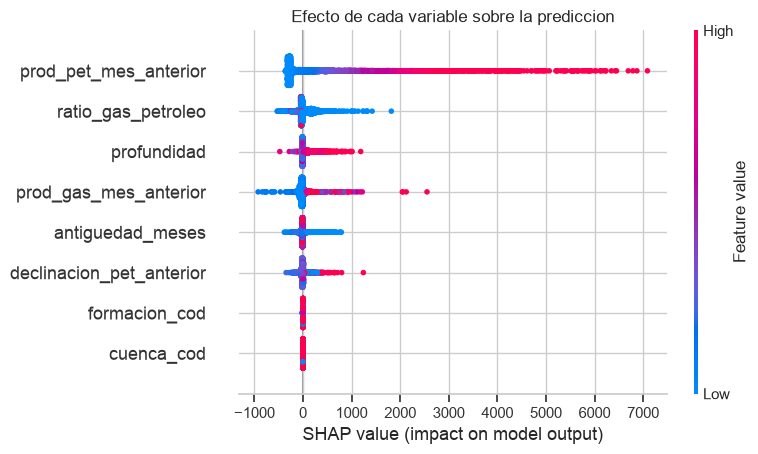

In [7]:
shap.plots.beeswarm(shap_values, show=False)
plt.title("Efecto de cada variable sobre la prediccion")
plt.tight_layout()
plt.savefig("reports/shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

## Paso 6: Como cambia el efecto segun el valor de la variable

Los graficos de dependencia muestran, para una variable, como cambia su
contribucion a medida que cambia su valor. Miramos las dos variables mas
importantes: la produccion del mes anterior y la antiguedad del pozo.

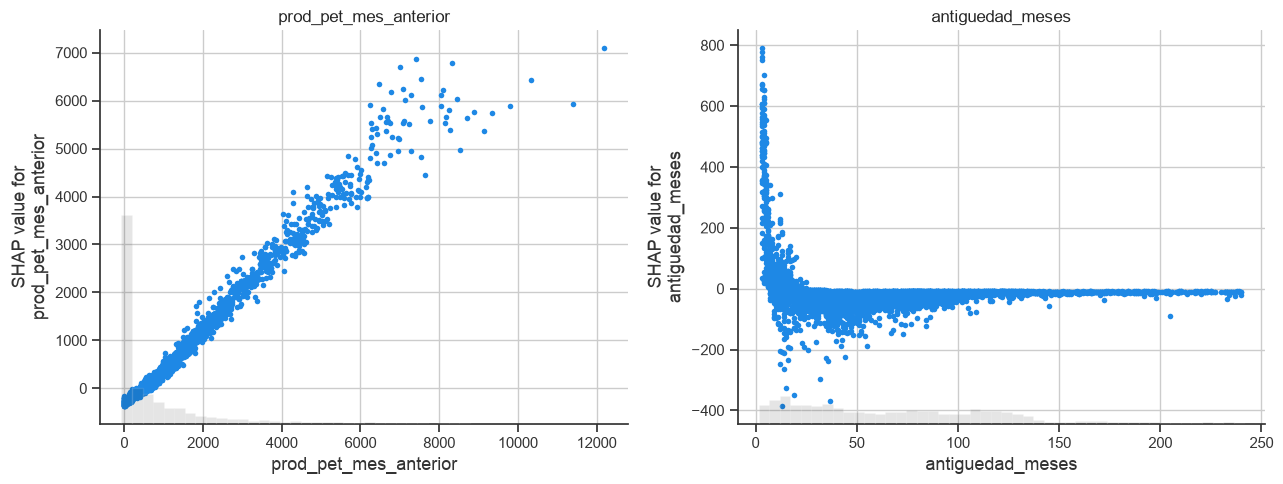

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

shap.plots.scatter(shap_values[:, "prod_pet_mes_anterior"], ax=axes[0], show=False)
axes[0].set_title("prod_pet_mes_anterior")

shap.plots.scatter(shap_values[:, "antiguedad_meses"], ax=axes[1], show=False)
axes[1].set_title("antiguedad_meses")

plt.tight_layout()
plt.savefig("reports/shap_dependencia.png", dpi=150, bbox_inches="tight")
plt.show()

## Paso 7: Explicar el caso mas problematico - pico alto subestimado

La limitacion conocida del modelo es que **subestima los pozos con picos
muy altos (>10.000)**. SHAP nos permite mirar un caso concreto: tomamos el
mes de mayor error por subestimacion en esos picos y vemos que variables
empujaron la prediccion, para entender *por que* se quedo corto.

In [9]:
# Meses de prueba con produccion real mayor a 10.000
mascara_picos = y_test > 10000
X_picos = X_test[mascara_picos]
y_picos = y_test[mascara_picos]
pred_picos = pd.Series(modelo.predict(X_picos), index=X_picos.index)

print("Meses con produccion real > 10.000:", len(X_picos))

# Caso con la mayor subestimacion (real - predicho)
error_picos = y_picos - pred_picos
indice_peor = error_picos.idxmax()

print("Produccion real:   ", round(float(y_picos[indice_peor]), 1))
print("Produccion predicha:", round(float(pred_picos[indice_peor]), 1))
print("Pozo:", int(df.loc[indice_peor, "idpozo"]), "| Antiguedad (meses):", int(X_picos.loc[indice_peor, "antiguedad_meses"]))

Meses con produccion real > 10.000: 60
Produccion real:    26593.3
Produccion predicha: 8775.0
Pozo: 164941 | Antiguedad (meses): 13


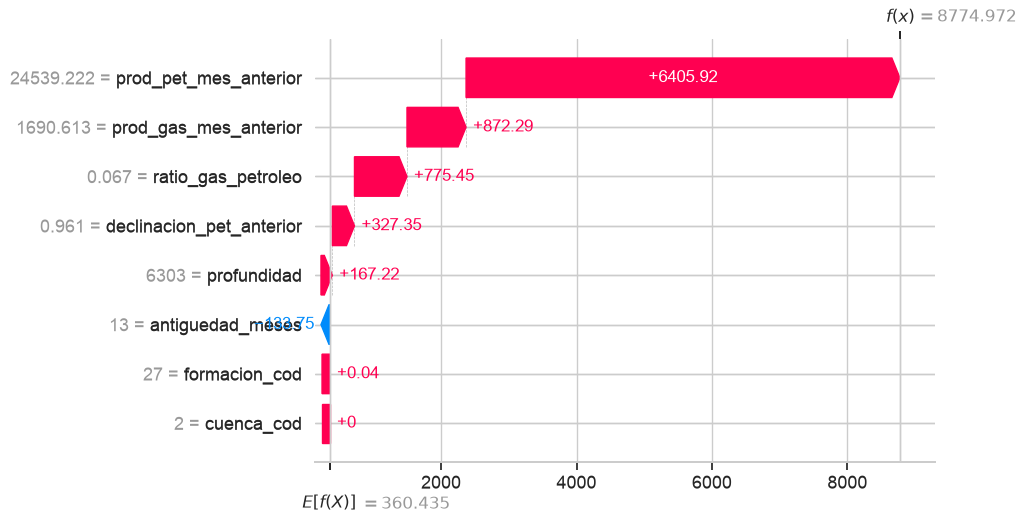

In [12]:
shap_peor = explainer(X_picos.loc[[indice_peor]])

plt.figure()  # figura nueva, para que no se mezcle con graficos anteriores
shap.plots.waterfall(shap_peor[0], show=False)
plt.savefig("reports/shap_caso_pico_subestimado.png", dpi=150, bbox_inches="tight")
plt.show()

**Como leer este grafico (waterfall):** parte del valor base (promedio del
modelo) abajo y va sumando o restando la contribucion de cada variable hasta
llegar a la prediccion final arriba. Comparamos esa prediccion final con la
produccion real que imprimimos arriba.

### Los picos altos en conjunto

Un solo caso puede ser una excepcion. Miramos entonces el patron en todos
los meses de pico alto del conjunto de prueba: el valor SHAP promedio de cada
variable (con signo), para ver que variables empujan la prediccion hacia
arriba o hacia abajo cuando la produccion real es muy alta.

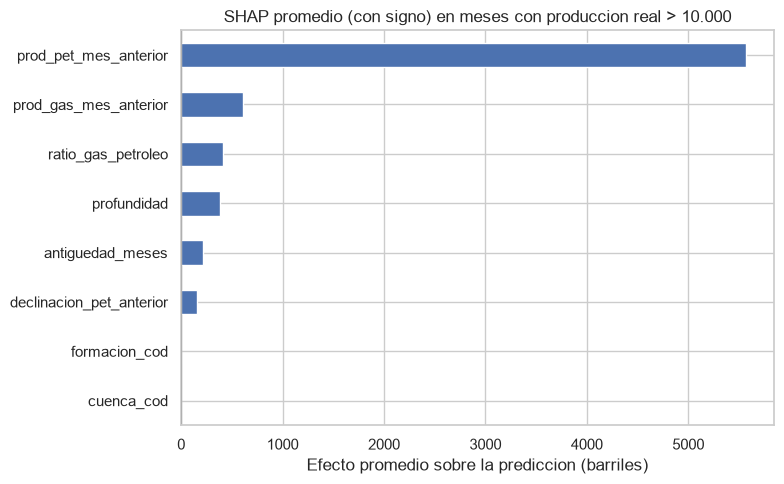

Prediccion promedio en picos: 7707.4
Produccion real promedio en picos: 12705.6


In [10]:
shap_picos = explainer(X_picos)

shap_promedio_picos = pd.Series(
    shap_picos.values.mean(axis=0), index=columnas_features
).sort_values()

plt.figure(figsize=(8, 5))
shap_promedio_picos.plot(kind="barh", color="#4C72B0")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("SHAP promedio (con signo) en meses con produccion real > 10.000")
plt.xlabel("Efecto promedio sobre la prediccion (barriles)")
plt.tight_layout()
plt.savefig("reports/shap_picos_altos.png", dpi=150, bbox_inches="tight")
plt.show()

print("Prediccion promedio en picos:", round(float(pred_picos.mean()), 1))
print("Produccion real promedio en picos:", round(float(y_picos.mean()), 1))

## Paso 8: Que tan raros eran los picos para el modelo

SHAP muestra que, en los picos, el modelo se apoya casi por completo en
`prod_pet_mes_anterior`. Una pregunta que sigue: ¿cuantos ejemplos de
produccion muy alta vio el modelo mientras entrenaba? Los modelos de arboles
(LightGBM, XGBoost) no pueden predecir por encima de lo que vieron en el
entrenamiento: no extrapolan, solo reparten valores que ya conocen.

In [13]:
print("Maximo de prod_pet en entrenamiento (hasta 2023):", round(train["prod_pet"].max(), 1))
print("Maximo de prod_pet en prueba (2024-2025):        ", round(test["prod_pet"].max(), 1))
print()
print("Filas de entrenamiento con prod_pet > 10.000:", (train["prod_pet"] > 10000).sum(), "de", len(train))
print("Filas de prueba con prod_pet > 10.000:       ", (test["prod_pet"] > 10000).sum(), "de", len(test))

Maximo de prod_pet en entrenamiento (hasta 2023): 15942.5
Maximo de prod_pet en prueba (2024-2025):         26593.3

Filas de entrenamiento con prod_pet > 10.000: 36 de 169097
Filas de prueba con prod_pet > 10.000:        60 de 65170


## Paso 9: 

In [15]:
# Baseline simple: predecir que este mes produce lo mismo que el mes anterior
pred_baseline = X_test["prod_pet_mes_anterior"]
pred_modelo = pd.Series(predicciones, index=X_test.index)

comparacion_baseline = pd.DataFrame({
    "Baseline (mes anterior)": [
        mean_absolute_error(y_test, pred_baseline),
        np.sqrt(mean_squared_error(y_test, pred_baseline)),
        r2_score(y_test, pred_baseline),
        (y_test[mascara_picos] - pred_baseline[mascara_picos]).mean(),
    ],
    "LightGBM final": [
        mean_absolute_error(y_test, pred_modelo),
        np.sqrt(mean_squared_error(y_test, pred_modelo)),
        r2_score(y_test, pred_modelo),
        (y_test[mascara_picos] - pred_modelo[mascara_picos]).mean(),
    ],
}, index=["MAE", "RMSE", "R2", "Error medio en picos > 10.000"]).round(3)

comparacion_baseline

,Baseline (mes anterior),LightGBM final
MAE,172.222,163.864
RMSE,459.052,439.341
R2,0.878,0.888
Error medio en picos > 10.000,1996.506,4998.215


## Conclusiones

*(Completar despues de correr el notebook y mirar los graficos. Los puntos
de abajo indican que responder; no escribir conclusiones que los graficos
no muestren.)*

- **Variable dominante:** completar con la variable de mayor SHAP del Paso 4
  y cuantos barriles mueve en promedio. Indicar si coincide con la
  importancia de LightGBM del notebook 03.
- **Direccion del efecto:** completar con lo que muestra el beeswarm del
  Paso 5 para las variables principales (si un valor alto sube o baja la
  prediccion).
- **Variables de poco aporte:** completar con las que casi no mueven la
  prediccion (SHAP cercano a cero) y si tiene sentido sacarlas.
- **Picos altos:** completar con lo que muestran el waterfall y el
  grafico de picos en conjunto sobre por que el modelo se queda corto.
- **Rango de entrenamiento:** completar con lo que muestra el Paso 8
  (maximo visto al entrenar contra maximo en prueba) y si esto cambia la
  explicacion de la limitacion de los picos altos del notebook 03.
- **Limitacion:** SHAP explica como usa el modelo las variables, no prueba
  causalidad: una variable importante para el modelo no es necesariamente la
  causa fisica de la produccion.

**Proximo paso:** optimizacion de hiperparametros del modelo supervisado
(Optuna) y Entrega Final (API con FastAPI, Dockerfile y README).

- Variable dominante: prod_pet_mes_anterior (SHAP promedio de 619 barriles,
  unas 5,6 veces la segunda, ratio_gas_petroleo con 111). LightGBM tambien la
  marcaba como la mas usada, pero por cantidad de splits sobrestima a
  declinacion_pet_anterior (2da mas usada, pero la de menor efecto real
  entre las variables que aportan).
- Direccion del efecto: valores altos de prod_pet_mes_anterior suben la
  prediccion de forma casi lineal, con un aplanamiento en valores altos. La
  antiguedad solo aporta en los primeros ~15 meses de vida del pozo.
- Variables de poco aporte: formacion_cod (0,7) y cuenca_cod (0) casi no
  mueven la prediccion; se podrian sacar del modelo sin perdida.
- Picos altos: en los meses con produccion real > 10.000 todas las variables
  empujan la prediccion hacia arriba (sobre todo prod_pet_mes_anterior), pero
  ese aporte se aplana: en el caso mas subestimado (pozo 164941) un mes
  anterior de 24.539 aporto +6.406 y el modelo predijo 8.775 contra 26.593 reales.
- Rango de entrenamiento: el maximo visto al entrenar fue 15.943 (36 filas
  con mas de 10.000 sobre 169.097) y en prueba hay picos de hasta 26.593. Los
  modelos de arboles no extrapolan, por lo que esto explica al menos en parte
  la subestimacion, ademas de la hipotesis de reestimulaciones del notebook 03.
- Limitacion: SHAP explica como usa el modelo las variables, no prueba
  causalidad.